# FS2 anonimizador - AnonyMED-BR
Avaliação do Anonimizador por Expressões Regulares



In [1]:
# Modulo I Experimento II

# Entidades avaliadas:
#   Números de Telefone
#   Endereços de E-mail
#   Nomes Pessoais avaliada no Módulo II


# 0. CONFIGURAÇÃO DO AMBIENTE - VERSÃO REPRODUTÍVEL PARA GITHUB

import os
import sys
import importlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import ConfusionMatrixDisplay

# Caminho raiz do projeto.
# Execute este notebook a partir da raiz do repositório.
BASE_DIR = os.getcwd()

ANONCUSTOM_DIR = os.path.join(BASE_DIR, "AnonCustomizado")
DATA_DIR = os.path.join(BASE_DIR, "data")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")

PATH_REGISTROS = os.path.join(DATA_DIR, "reg_novos_med.xlsx")
PATH_GABARITO = os.path.join(DATA_DIR, "gabarito_base_dados_medica_corrigido.xlsx")

COL_TEXTO = "relato"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Torna o extracao.py importável
if ANONCUSTOM_DIR not in sys.path:
    sys.path.append(ANONCUSTOM_DIR)

import extracao
importlib.reload(extracao)

print("Ambiente configurado.")
print(f"Diretório base: {BASE_DIR}")
print(f"Arquivo de registros: {PATH_REGISTROS}")
print(f"Arquivo de gabarito: {PATH_GABARITO}")
print(f"extracao.py: {extracao.__file__}")



Ambiente configurado.
Diretório base: c:\Users\MARISA STIC\OneDrive\Documentos\AnonimizadorFS2_JBCS
Arquivo de registros: c:\Users\MARISA STIC\OneDrive\Documentos\AnonimizadorFS2_JBCS\data\reg_novos_med.xlsx
Arquivo de gabarito: c:\Users\MARISA STIC\OneDrive\Documentos\AnonimizadorFS2_JBCS\data\gabarito_base_dados_medica_corrigido.xlsx
extracao.py: c:\Users\MARISA STIC\OneDrive\Documentos\AnonimizadorFS2_JBCS\AnonCustomizado\extracao.py


In [2]:
# 1. CARREGAMENTO DOS DADOS


df_bos   = pd.read_excel(PATH_REGISTROS)
gabarito = pd.read_excel(PATH_GABARITO)

df_bos   = df_bos.rename(columns={"reg_med_key": "crime_bop_key"})
gabarito = gabarito.rename(columns={"reg_med_key": "crime_bop_key"})

assert COL_TEXTO in df_bos.columns, f"Coluna '{COL_TEXTO}' não encontrada."

print(f"Registros médicos : {df_bos.shape}")
print(f"Gabarito          : {gabarito.shape}")

Registros médicos : (1886, 6)
Gabarito          : (1886, 5)


In [3]:
# 2. EXTRAÇÃO DE ENTIDADES (AnonCustomizado)



df_tel   = extracao.telefone(df_bos[COL_TEXTO])
df_email = extracao.email(df_bos[COL_TEXTO])

extr = pd.concat(
    [df_bos[[COL_TEXTO, "crime_bop_key"]],  df_tel, df_email],
    axis=1
)

print("Extração concluída.")
print(f"Colunas extr: {list(extr.columns)}")

Extração concluída.
Colunas extr: ['relato', 'crime_bop_key', 'TELEFONE', 'EMAIL']


In [4]:
# 3. NORMALIZAÇÃO DE TELEFONE E E-MAIL

EMAIL_RE = re.compile(r'(?i)\b[A-Z0-9._%+\-]+@[A-Z0-9.\-]+\.[A-Z]{2,}\b')

def _preprocess_telefone(x):
    """Remove letras e normaliza separadores no campo de telefone bruto."""
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return x
    s = str(x)
    s = re.sub(r'[A-Za-zÀ-ÿ]', '', s)
    s = re.sub(r'(\(\d{2}\))\s*,\s*', r'\1 ', s)
    s = re.sub(r'(?<!\d)(\d{2}),\s*(?=\d)', r'\1 ', s)
    return re.sub(r' +', ' ', s).strip()


def _normalize_telefone_extracao(x):
    """Normaliza telefone extraído do relato (sem parênteses no DDD)."""
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return ""
    candidates = re.findall(r'\+?\d[\d\-\s\(\)\.]*\d', str(x))
    seen, out = set(), []
    for c in candidates:
        digits = re.sub(r'\D', '', c)
        if digits.startswith("55") and len(digits) in (12, 13):
            digits = digits[2:]
        if len(digits) in (10, 11) and digits not in seen:
            seen.add(digits)
            out.append(digits)
    return "; ".join(out)


def _normalize_telefone_gabarito(x):
    """Normaliza telefone do gabarito (DDD pode estar entre parênteses)."""
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return ""
    s = str(x)
    s = re.sub(r'\((\d{2})\)\s*', r'\1', s)
    s = re.sub(r'(?<!\d)(\d{2})\s+(?=\d)', r'\1', s)
    candidates = re.findall(r'\+?\d[\d\-\s]*\d', s)
    seen, out = set(), []
    for c in candidates:
        digits = re.sub(r'\D', '', c)
        if digits.startswith("55") and len(digits) in (12, 13):
            digits = digits[2:]
        if len(digits) in (10, 11) and digits not in seen:
            seen.add(digits)
            out.append(digits)
    return "; ".join(out)


def _normalize_email(x):
    """Normaliza e-mail para minúsculo, remove duplicatas."""
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return ""
    emails = [e.lower() for e in EMAIL_RE.findall(str(x).strip())]
    seen, out = set(), []
    for e in emails:
        if e not in seen:
            seen.add(e)
            out.append(e)
    return "; ".join(out)


# Aplica normalização
gabarito["TELEFONE"] = gabarito["TELEFONE"].apply(_preprocess_telefone).apply(_normalize_telefone_gabarito)
extr["TELEFONE"]     = extr["TELEFONE"].apply(_normalize_telefone_extracao)
gabarito["EMAIL"]    = gabarito["EMAIL"].apply(_normalize_email)
extr["EMAIL"]        = extr["EMAIL"].apply(_normalize_email)

print("Normalização concluída.")


Normalização concluída.


In [5]:
# 5. TOKENIZADORES

_RE_TOKEN = re.compile(
    r"""([#]?[@\w''\+\-.,]*[\w][$]?|[:;<]\-?[\)\(3])""",
    re.VERBOSE
)
_PHONE_DIGITS_RE = re.compile(r'(?<!\d)\d{10,11}(?!\d)')


def tokenize_general(text):

    return _RE_TOKEN.findall(str(text))

def tokenize_phone(text):

    if text is None or (isinstance(text, float) and pd.isna(text)):
        return []
    matches = re.findall(
        r'(?:\+?55\s*)?(?:\(?\d{2}\)?\s*)?\d{4,5}[-\s]?\d{4}',
        str(text)
    )
    tokens = []
    for m in matches:
        digits = re.sub(r'\D', '', m)
        if digits.startswith("55") and len(digits) in (12, 13):
            digits = digits[2:]
        if len(digits) in (10, 11):
            tokens.append(digits)
    return tokens


def tokenize_email(text):

    return EMAIL_RE.findall(str(text).lower())


def safe_tokenize(cell, tokenizer):

    if cell is None or (isinstance(cell, float) and pd.isna(cell)):
        return []
    s = str(cell).strip()
    if not s or s.lower() == "nan":
        return []
    return [t for t in tokenizer(s) if str(t).strip()]

In [6]:
# 6. CÁLCULO DE MÉTRICAS

def _calcular_tp_tn_fp_fn(relato, true_tokens, pred_tokens):

    true_c = Counter(true_tokens)
    pred_c = Counter(pred_tokens)
    tp = sum(min(true_c[t], pred_c[t]) for t in true_c)
    fn = sum(true_c[t] - pred_c.get(t, 0) for t in true_c)
    fp = sum(pred_c[t] - true_c.get(t, 0) for t in pred_c)
    universo = len(safe_tokenize(relato, tokenize_general))
    tn = max(0, universo - tp - fp - fn)
    return tp, tn, fp, fn


def sum_of_classifications(extracao_alvo, gabarito_alvo, extracao_relato,
                            tokenizer_pred, tokenizer_true):

    tp = tn = fp = fn = 0
    for relato, pred_cell, true_cell in zip(extracao_relato,
                                             extracao_alvo,
                                             gabarito_alvo):
        true_tokens = safe_tokenize(true_cell, tokenizer_true)
        pred_tokens = safe_tokenize(pred_cell, tokenizer_pred)
        a, b, c, d = _calcular_tp_tn_fp_fn(relato, true_tokens, pred_tokens)
        tp += a; tn += b; fp += c; fn += d
    return tp, tn, fp, fn


def metrics_from_counts(tp, tn, fp, fn):

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1        = (2 * precision * recall / (precision + recall)) \
                if (precision + recall) else 0.0
    acc       = (tp + tn) / (tp + tn + fp + fn) \
                if (tp + tn + fp + fn) else 0.0
    return acc, precision, recall, f1

In [7]:

# 7. ESTATÍSTICAS DESCRITIVAS DO CORPUS


tokens_por_doc  = df_bos[COL_TEXTO].apply(lambda x: tokenize_general(x))
qtd_por_doc     = tokens_por_doc.apply(len)
todos_tokens    = [t for lista in tokens_por_doc for t in lista]

def _count_sep(series, sep):
    return int(series.fillna("").astype(str).apply(
        lambda x: len([t for t in x.split(sep) if t.strip() and t.strip().lower() != "nan"])
    ).sum())


total_telefones = _count_sep(gabarito["TELEFONE"], ";")
total_emails    = _count_sep(gabarito["EMAIL"],    ";")
total_tokens    = int(qtd_por_doc.sum())

df_stats = pd.DataFrame({
    "Métrica": [
        "Documentos (Registros Médicos)",
        "Tokens totais",
        "Maior qtd. de tokens por RM",
        "Menor qtd. de tokens por RM",
        "Média de tokens por RM",
        "Desvio padrão de tokens",
        "Telefones anotados",
        "E-mails anotados",

    ],
    "Valor": [
        len(df_bos),
        total_tokens,
        int(qtd_por_doc.max()),
        int(qtd_por_doc.min()),
        round(qtd_por_doc.mean(), 2),
        round(qtd_por_doc.std(),  2),
        total_telefones,
        total_emails,

    ]
})
display(df_stats)


,Métrica,Valor
0,Documentos (Registros Médicos),1886.00
1,Tokens totais,369794.00
2,Maior qtd. de tokens por RM,498.00
3,Menor qtd. de tokens por RM,46.00
4,Média de tokens por RM,196.07
5,Desvio padrão de tokens,82.37
6,Telefones anotados,1913.00
7,E-mails anotados,1472.00


In [8]:
# 7 - CÁLCULO DAS MÉTRICAS E TABELA DE RESULTADOS


ENTIDADES = [
    ("M1", "Números de Telefones", "TELEFONE", tokenize_phone,   tokenize_phone),
    ("M2", "Endereços de E-mail",  "EMAIL",    tokenize_email,   tokenize_email),
]

resultados = []

for cod, titulo, col, tok_pred, tok_true in ENTIDADES:

    tp, tn, fp, fn = sum_of_classifications(
        extracao_alvo   = extr[col].fillna(""),
        gabarito_alvo   = gabarito[col].fillna(""),
        extracao_relato = extr[COL_TEXTO].fillna(""),
        tokenizer_pred  = tok_pred,
        tokenizer_true  = tok_true,
    )

    acc, precision, recall, f1 = metrics_from_counts(
        tp, tn, fp, fn
    )

    resultados.append([
        cod,
        titulo,
        acc,
        precision,
        recall,
        f1,
        tp,
        tn,
        fp,
        fn
    ])

df_res = pd.DataFrame(
    resultados,
    columns=[
        "Matriz",
        "Titulo",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "TP",
        "TN",
        "FP",
        "FN"
    ]
)

tot_gab = {
    "M1": _count_sep(gabarito["TELEFONE"], ";"),
    "M2": _count_sep(gabarito["EMAIL"], ";"),
}

tot_ext = {
    "M1": _count_sep(extr["TELEFONE"], ";"),
    "M2": _count_sep(extr["EMAIL"], ";"),
}

df_res["Total Gabarito"] = df_res["Matriz"].map(tot_gab)
df_res["Total Extraído"] = df_res["Matriz"].map(tot_ext)
df_res["Total Tokens"] = total_tokens

pd.options.display.float_format = "{:.4f}".format

display(
    df_res[
        [
            "Matriz",
            "Titulo",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "TN",
            "FP",
            "FN",
            "TP",
            "Total Gabarito",
            "Total Extraído",
            "Total Tokens"
        ]
    ]
)

,Matriz,Titulo,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Total Gabarito,Total Extraído,Total Tokens
0,M1,Números de Telefones,1.0000,1.0000,0.9906,0.9953,367881,0,18,1895,1913,1895,369794
1,M2,Endereços de E-mail,1.0000,0.9966,0.9966,0.9966,368317,5,5,1467,1472,1472,369794


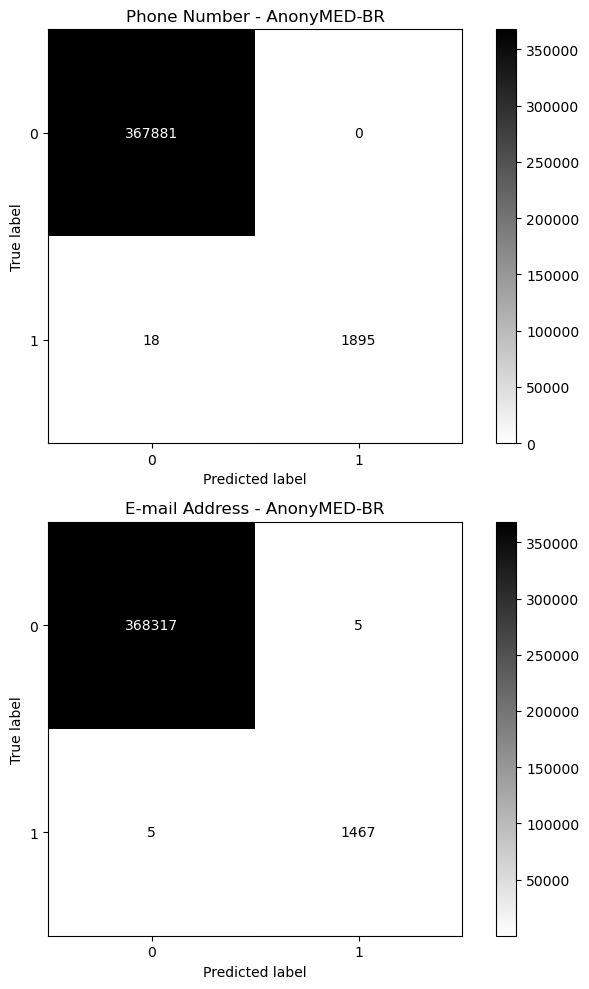

In [9]:
# 8. matrizes

tp_ph, tn_ph, fp_ph, fn_ph = sum_of_classifications(
    extracao_alvo   = extr["TELEFONE"].fillna(""),
    gabarito_alvo   = gabarito["TELEFONE"].fillna(""),
    extracao_relato = extr[COL_TEXTO].fillna(""),
    tokenizer_pred  = tokenize_phone,
    tokenizer_true  = tokenize_phone,
)

tp_em, tn_em, fp_em, fn_em = sum_of_classifications(
    extracao_alvo   = extr["EMAIL"].fillna(""),
    gabarito_alvo   = gabarito["EMAIL"].fillna(""),
    extracao_relato = extr[COL_TEXTO].fillna(""),
    tokenizer_pred  = tokenize_email,
    tokenizer_true  = tokenize_email,
)

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(7, 10))

for ax, cm_vals, title in [
    (axes[0], (tn_ph, fp_ph, fn_ph, tp_ph), "Phone Number - AnonyMED-BR"),
    (axes[1], (tn_em, fp_em, fn_em, tp_em), "E-mail Address - AnonyMED-BR"),
]:
    tn_, fp_, fn_, tp_ = cm_vals

    cm_ = np.array([
        [tn_, fp_],
        [fn_, tp_]
    ])

    ConfusionMatrixDisplay(
        confusion_matrix=cm_,
        display_labels=[0, 1]
    ).plot(
        cmap="binary",
        ax=ax,
        colorbar=True
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()